In [1]:
import math
from pathlib import Path

import numpy as np
import torch
import torch.nn.functional as F
from IPython.display import Markdown, display
from PIL import Image, ImageDraw

CUBE_PATH = Path('./outputs/studio_small_09_cube_from_fibonacci/cubemap.npz')
OUTPUT_PATH = Path('./outputs/studio_small_09_fibonacci_from_cube.npz')
NUM_SAMPLES = None  # Use the source count when available.
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

FACE_FILES = ('posx.png', 'negx.png', 'posy.png', 'negy.png', 'posz.png', 'negz.png')

In [2]:
def fibonacci_directions(num_samples, device, dtype):
    """Return unit directions [N, 3] ordered from +Y toward -Y."""
    if not isinstance(num_samples, int) or isinstance(num_samples, bool) or num_samples < 1:
        raise ValueError('num_samples must be a positive integer')

    # Keep the longitude phase accurate before casting to the image dtype.
    index = torch.arange(num_samples, device=device, dtype=torch.float64)
    y = 1 - 2 * (index + 0.5) / num_samples
    radius = torch.sqrt((1 - y) * (1 + y))
    golden_angle = math.pi * (3 - math.sqrt(5))
    theta = torch.remainder(index * golden_angle, 2 * math.pi)
    directions = torch.stack((radius * theta.sin(), y, radius * theta.cos()), dim=-1)
    return directions.to(dtype=dtype)


def directions_to_erp_uv(directions):
    """Map unit directions to ERP coordinates measured from the image edges."""
    x, y, z = directions.unbind(dim=-1)
    u = torch.atan2(x, z) / (2 * math.pi) + 0.5
    v = 0.5 - torch.asin(y.clamp(-1, 1)) / math.pi
    return u, v

In [3]:
def cubemap_to_fibonacci(cubemap, num_samples):
    """Sample [B, 6, 3, S, S] and return directions [N, 3] and RGB [B, N, 3]."""
    if cubemap.ndim != 5:
        raise ValueError('Expected cubemap shape [B, 6, 3, S, S]')
    batch, face_count, channels, height, width = cubemap.shape
    if face_count != 6 or channels != 3 or height != width or min(batch, height) < 1:
        raise ValueError(f'Expected six nonempty square RGB faces, got {tuple(cubemap.shape)}')
    if cubemap.dtype not in (torch.float32, torch.float64):
        raise TypeError('Use float32 or float64 for cubemap values')
    if not torch.isfinite(cubemap).all():
        raise ValueError('Cubemap contains non-finite values')

    directions = fibonacci_directions(num_samples, cubemap.device, cubemap.dtype)
    x, y, z = directions.unbind(dim=-1)
    axis = directions.abs().argmax(dim=-1, keepdim=True)
    dominant = directions.gather(-1, axis).squeeze(-1)
    face_indices = 2 * axis.squeeze(-1) + (dominant < 0).long()
    # Right and down components in +X, -X, +Y, -Y, +Z, -Z order.
    face_coordinates = ((-z, -y), (z, -y), (x, z), (x, -z), (x, -y), (-x, -y))

    rgb = cubemap.new_empty(batch, num_samples, channels)
    for index, (u, v) in enumerate(face_coordinates):
        mask = face_indices == index
        coordinates = torch.stack((u[mask], v[mask]), dim=-1)
        if coordinates.numel() == 0:
            continue
        coordinates = coordinates / dominant[mask].abs().unsqueeze(-1)
        grid = coordinates.reshape(1, 1, -1, 2).expand(batch, -1, -1, -1)
        sampled = F.grid_sample(
            cubemap[:, index], grid, mode='bilinear',
            padding_mode='border', align_corners=False,
        )
        rgb[:, mask, :] = sampled.squeeze(2).transpose(1, 2)
    return directions, rgb

In [4]:
def load_cubemap(path, device):
    """Read cube data and return its suggested Fibonacci sample count."""
    if path.is_dir():
        faces = []
        expected_size = None
        for filename in FACE_FILES:
            face_path = path / filename
            if not face_path.is_file():
                raise FileNotFoundError(f'Missing cubemap face: {face_path.resolve()}')
            with Image.open(face_path) as face:
                if expected_size is None:
                    expected_size = face.size
                if face.width != face.height or face.size != expected_size:
                    raise ValueError(f'All faces must have the same square size. {face_path} is {face.size}')
                faces.append(np.asarray(face.convert('RGB')))
        pixels = torch.from_numpy(np.stack(faces)).permute(0, 3, 1, 2).unsqueeze(0)
        return pixels.to(device=device, dtype=torch.float32) / 255, 4096

    with np.load(path, allow_pickle=False) as data:
        num_samples = int(data['num_samples'].item()) if 'num_samples' in data else 4096
        return torch.from_numpy(data['cubemap']).to(device), num_samples


cube, source_count = load_cubemap(CUBE_PATH, DEVICE)
num_samples = source_count if NUM_SAMPLES is None else NUM_SAMPLES
directions, rgb = cubemap_to_fibonacci(cube, num_samples)
print('Cubemap:', tuple(cube.shape), 'device:', cube.device)
print('Directions:', tuple(directions.shape), 'RGB:', tuple(rgb.shape))
print('Sampled RGB range:', (rgb.min().item(), rgb.max().item()))

Cubemap: (1, 6, 3, 512, 512) device: cuda:0
Directions: (32768, 3) RGB: (1, 32768, 3)
Sampled RGB range: (0.0010802410542964935, 322.39263916015625)


Saved: E:\model\erpProcess\outputs\studio_small_09_fibonacci_from_cube.npz


**Cubemap 采样点在 ERP 上的位置与颜色**

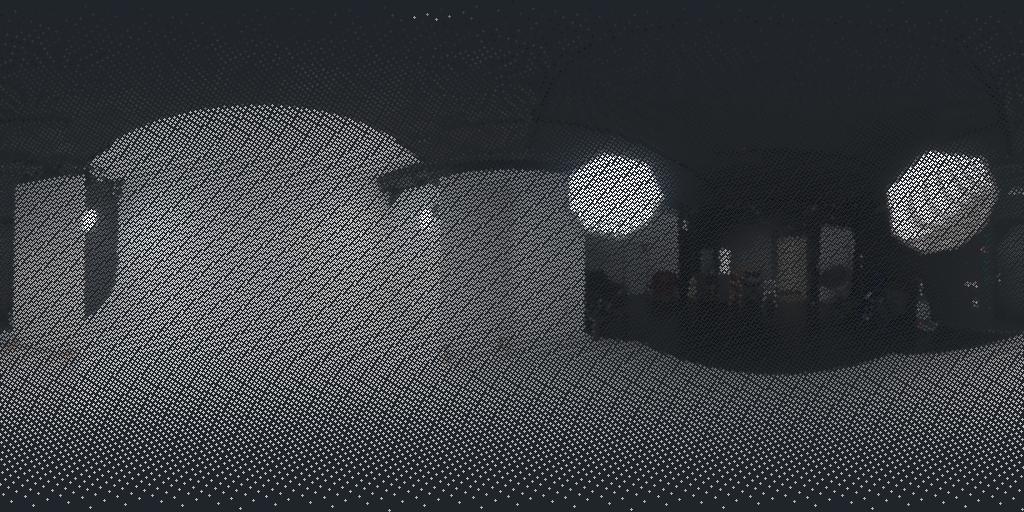

In [5]:
rgb_values = rgb.detach().cpu().numpy()
OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)
np.savez_compressed(OUTPUT_PATH, directions=directions.cpu().numpy(), rgb=rgb_values)
print('Saved:', OUTPUT_PATH.resolve())

# Plot the samples in ERP coordinates for display.
preview = Image.new('RGB', (1024, 512), '#20242b')
draw = ImageDraw.Draw(preview)
u, v = directions_to_erp_uv(directions)
columns = (u.remainder(1) * preview.width).long().cpu().tolist()
rows = (v * preview.height).long().clamp(max=preview.height - 1).cpu().tolist()
colors = rgb_values[0]
if not CUBE_PATH.is_dir():
    colors = np.maximum(colors, 0)
    colors = (colors / (1 + colors)) ** (1 / 2.2)
colors = np.rint(colors * 255).astype(np.uint8).tolist()
for column, row, color in zip(columns, rows, colors):
    draw.ellipse((column - 1, row - 1, column + 1, row + 1), fill=tuple(color))

display(Markdown('**Cubemap 采样点在 ERP 上的位置与颜色**'), preview)